In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

from utilities import find_peaks, wideband_pulse, MyPolygonSelector, field_to_timeseries
import warping

In [3]:
from visualization_tools import SelectFromCollection

In [4]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
from scipy.ndimage import label

from matplotlib.widgets import Button

In [5]:
%matplotlib widget

In [6]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [7]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.3

#NPERSEG = 200
WINDOW = sp.windows.hann

NPEAKS = 20

SNRDB = 50

In [8]:
wb_pulse_params = dict(pulse_duration=0.1, fs=SAMPLING_FREQ, bw=200, fc=350, window=sp.windows.hann)

In [9]:
replica1 = scipy.io.loadmat("../data/field_values20260921/field_values20260921.mat")

In [10]:
data1 = scipy.io.loadmat("../data/field_values20260921/field_values20260921.mat")

f = data1['f'].squeeze()
c = data1['soundspeed'].squeeze()
rho = data1['rho'].squeeze()
Vg = data1['Vg'][:,:,c == TRUE_SOUNDSPEED,:,rho==TRUE_DENSITY,...].squeeze()
source_range = data1['range'][0,0] * 1e3
f_Vg = f[1:-1]

X = data1['g'][0,0,c==TRUE_SOUNDSPEED,0,rho==TRUE_DENSITY,:].squeeze()

In [11]:
t0 = source_range/1500
N= 2000

x0, tx = field_to_timeseries(X, f, t0, N, SAMPLING_FREQ)

In [12]:
rng = np.random.RandomState(30)
noisemag = 10**(-SNRDB/20)
x0 = x0 + np.linalg.norm(x0)*noisemag*rng.normal(size=x0.shape)

In [13]:
stft1_short_window = sp.ShortTimeFFT.from_window(
    'hann', SAMPLING_FREQ, 80, 80-1, mfft = 2000)

stft1_long_window = sp.ShortTimeFFT.from_window(
    'hann', SAMPLING_FREQ, 200, 200-1, mfft = 2000)

In [14]:
fmask = np.all(np.array([stft1_short_window.f>=200, stft1_short_window.f<=500]), axis=0)

w = stft1_short_window.f[fmask]

In [15]:
t_short = stft1_short_window.t(len(x0)) + t0
t_long = stft1_long_window.t(len(x0)) + t0

In [16]:
t_short

array([6.64716667, 6.64766667, 6.64816667, ..., 7.68466667, 7.68516667,
       7.68566667], shape=(2078,))

## Full Signal

In [17]:
X0_short = stft1_short_window.stft( np.real(x0.squeeze()))[fmask,:]
X0_long = stft1_long_window.stft( np.real(x0.squeeze()))[fmask,:]

In [18]:
peaksx_short = find_peaks(np.abs(X0_short)**2, w, t_short, 17)
peaksx_long = find_peaks(np.abs(X0_long)**2, w, t_long, 17)

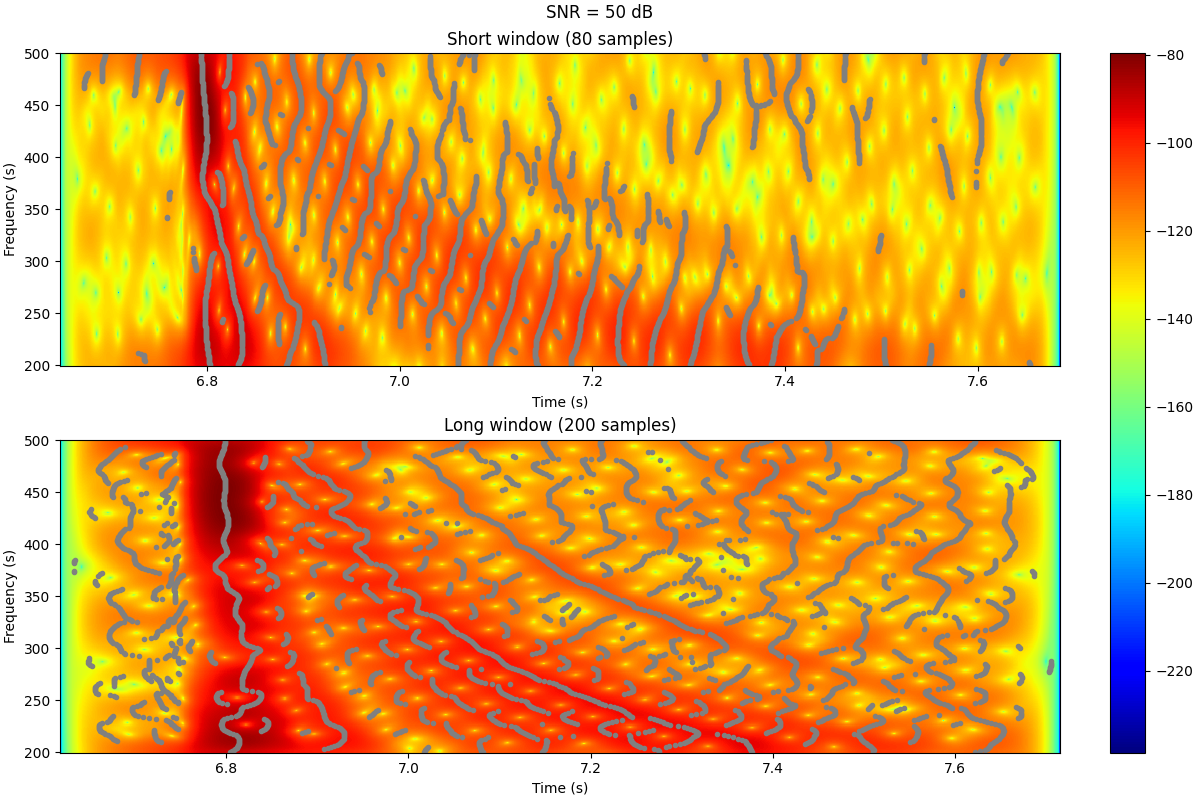

In [19]:
fig, ax = plt.subplots(2,1, layout = 'constrained')

m1 = ax[0].pcolormesh(t_short, w, 10*np.log10(np.abs(X0_short)**2), cmap='jet')
ax[0].scatter(peaksx_short[:,0], peaksx_short[:,1], marker='.', c="grey")


ax[0].set_title(f'Short window (80 samples)')
ax[0].set_xlabel('Time (s)')
ax[0].set_ylabel('Frequency (s)')

m1 = ax[1].pcolormesh(t_long, w, 10*np.log10(np.abs(X0_long)**2), cmap='jet')
ax[1].scatter(peaksx_long[:,0], peaksx_long[:,1], marker='.', c="grey")

ax[1].set_title(f'Long window (200 samples)')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Frequency (s)')

fig.colorbar(m1, ax=ax)

fig.set_size_inches([12,8])

fig.suptitle(f'SNR = {SNRDB} dB')

fig.savefig(f'../data/output/figures/noisy_spectrogram{SNRDB}db.png', dpi=300)

plt.show()

### Manually sorting the peaks

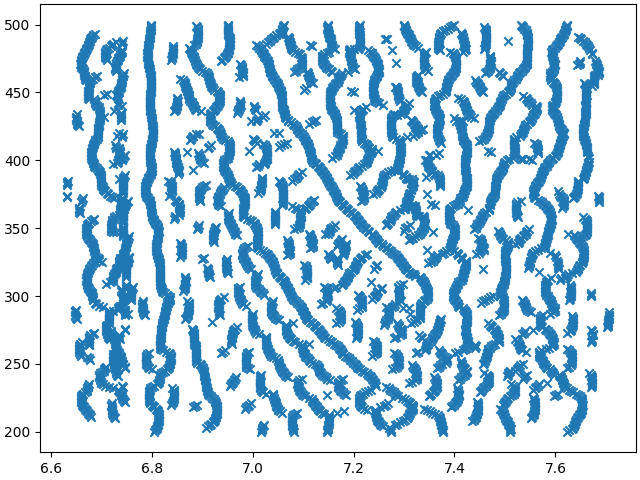

In [25]:
fig, ax = plt.subplots(layout = 'constrained')

points = ax.scatter(peaksx_long[:,0], peaksx_long[:,1], marker = 'x')

In [21]:
selector_short = MyPolygonSelector(ax)

In [24]:
selector_short.select()

In [26]:
selector_long = MyPolygonSelector(ax)

In [33]:
selector_long.select()

In [34]:
polygons = selector_short.polygons + selector_long.polygons

In [35]:
classified_peaks = [peaksx_short[poly.contains_points(peaksx_short),:] for poly in selector_short.polygons]\
+ [peaksx_long[poly.contains_points(peaksx_long),:] for poly in selector_long.polygons[1:]]
 

(6.78, 7.5)

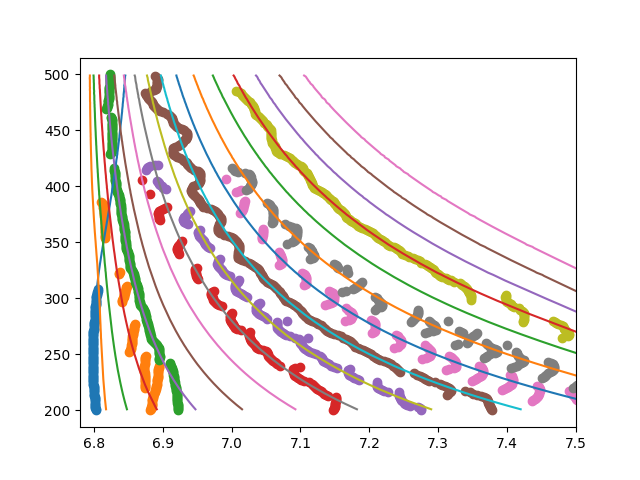

In [36]:
fig, ax = plt.subplots()

ax.plot(source_range/Vg.T, f_Vg)

for p in classified_peaks:
    ax.scatter(p[:,0], p[:,1])

ax.set_xlim([6.78,7.5])

In [37]:
classified_peaks = np.array([p[:, [1,0]] for p in classified_peaks], dtype=object)

In [38]:
export = {'peaks_coordinates':classified_peaks, 'mode_nos':np.array([1,4,5,8,9,10,11,12,14])}

np.savez(f'../data/output/stft_arrival_times_snr{SNRDB}.npz', **export)